# Desafío Data Scientist MRNF: Optimización con Optuna, Red Tabular con Auto-Atención y Explicabilidad SHAP
**Área:** Modelos de Riesgo No Financiero (MRNF)  
**Objetivo:** Desarrollar una etapa avanzada e independiente de modelado predictivo de fraude con tres pilares:
1. **Optimización Bayesiana (Optuna - 50 Trials):** Búsqueda sistemática de hiperparámetros para LightGBM y XGBoost maximizando PR-AUC sobre validación temporal.
2. **Red Tabular con Multi-Head Self-Attention (PyTorch + Focal Loss):** Arquitectura de deep learning que proyecta variables tabulares, calcula interacciones cruzadas vía auto-atención y entrena con función de costo ponderada ante el desbalance extremo (0.29%).
3. **Explicabilidad Integral con SHAP y Mapas de Atención:** Cálculo de TreeSHAP sobre el conjunto Out-of-Time y extracción de matrices de atención inter-variable, visualizados con gráficos interactivos Plotly y figuras nativas SHAP.
4. **Calibración Financiera:** Optimización de umbrales bajo la función económica: $\text{Utilidad} = 120\cdot\text{VP} - 30\cdot\text{FP} - 180\cdot\text{FN}$.

## 1. Configuración de Entorno y Carga de Datos Out-of-Time

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl

current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PROCESSED_DATA_PATH,
    RANDOM_STATE,
    TARGET_COL,
    TEST_OOT_END_DT,
    TEST_OOT_START_DT,
    TRAIN_START_DT,
    VAL_START_DT,
)
from src.models.attention import TabularAttentionClassifier
from src.models.evaluation import (
    compute_detailed_metrics,
    find_optimal_business_threshold,
    plot_business_utility_tradeoff,
    plot_precision_recall_curves,
    plot_roc_curves,
)
from src.models.explainability import (
    compute_tree_shap_values,
    plot_attention_heatmap_plotly,
    plot_shap_dependence_plotly,
    plot_shap_summary_plotly,
    save_figure_html,
)
from src.models.preprocessing import ALL_MODEL_FEATURES, create_preprocessor
from src.models.trainer import ModelEvaluationResult
from src.models.tuning import tune_lightgbm, tune_xgboost

print("Cargando dataset enriquecido con variables causales...")
df = pl.read_parquet(PROCESSED_DATA_PATH)

# Partición cronológica estricta
train_df = df.filter(
    (pl.col("timestamp") >= TRAIN_START_DT) & (pl.col("timestamp") < VAL_START_DT)
)
val_df = df.filter(
    (pl.col("timestamp") >= VAL_START_DT) & (pl.col("timestamp") < TEST_OOT_START_DT)
)
test_df = df.filter(
    (pl.col("timestamp") >= TEST_OOT_START_DT)
    & (pl.col("timestamp") <= TEST_OOT_END_DT)
)

print(
    f"Train set (Marzo - Mediados Abril): {train_df.height:,} tx | Fraudes: {train_df[TARGET_COL].sum():,} ({train_df[TARGET_COL].mean() * 100:.3f}%)"
)
print(
    f"Val set   (Mediados Abril - Fin Abril): {val_df.height:,} tx | Fraudes: {val_df[TARGET_COL].sum():,} ({val_df[TARGET_COL].mean() * 100:.3f}%)"
)
print(
    f"Test OOT  (Mayo 2026):               {test_df.height:,} tx | Fraudes: {test_df[TARGET_COL].sum():,} ({test_df[TARGET_COL].mean() * 100:.3f}%)"
)

c:\Users\vicen\anaconda3\envs\test-bci\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargando dataset enriquecido con variables causales...
Train set (Marzo - Mediados Abril): 508,522 tx | Fraudes: 1,695 (0.333%)
Val set   (Mediados Abril - Fin Abril): 167,210 tx | Fraudes: 473 (0.283%)
Test OOT  (Mayo 2026):               325,325 tx | Fraudes: 945 (0.290%)


## 2. Preprocesamiento Vectorizado sin Fuga Temporal

In [2]:
X_train = train_df.select(ALL_MODEL_FEATURES).to_pandas()
y_train = train_df[TARGET_COL].to_pandas().to_numpy()

X_val = val_df.select(ALL_MODEL_FEATURES).to_pandas()
y_val = val_df[TARGET_COL].to_pandas().to_numpy()

X_test = test_df.select(ALL_MODEL_FEATURES).to_pandas()
y_test = test_df[TARGET_COL].to_pandas().to_numpy()

preprocessor = create_preprocessor(random_state=RANDOM_STATE)
Xt_train = preprocessor.fit_transform(X_train, y_train)
Xt_val = preprocessor.transform(X_val)
Xt_test = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out().tolist()
print(f"Total variables transformadas: {Xt_train.shape[1]}")
print("Variables:", feature_names)

Total variables transformadas: 33
Variables: ['amount', 'delta_time_last_tx', 'card_tx_count_1h', 'card_tx_count_24h', 'card_tx_count_7d', 'card_amount_sum_1h', 'card_amount_sum_24h', 'card_amount_sum_7d', 'ratio_amount_mean_7d', 'cards_seen_by_device_24h', 'cards_seen_by_ip_24h', 'is_country_mismatch', 'is_high_risk_mcc', 'is_swipe', 'is_digital_channel', 'is_night_transaction', 'is_first_card_tx', 'channel_APP', 'channel_ATM', 'channel_ECOMMERCE', 'channel_POS', 'entry_mode_atm', 'entry_mode_chip', 'entry_mode_contactless', 'entry_mode_ecommerce', 'entry_mode_in_app', 'entry_mode_keyed', 'entry_mode_swipe', 'mcc', 'timestamp_hour_sin', 'timestamp_hour_cos', 'timestamp_day_sin', 'timestamp_day_cos']


## 3. Optimización Bayesiana con Optuna (50 Trials por Modelo de Árbol)
Optuna ajusta sistemáticamente los hiperparámetros clave de regularización, profundidad y ponderación de clases maximizando el **PR-AUC** sobre el conjunto de validación temporal.

In [3]:
print("Iniciando optimización con Optuna para LightGBM (50 trials)...")
optuna_lgb = tune_lightgbm(
    x_train=Xt_train,
    y_train=y_train,
    x_val=Xt_val,
    y_val=y_val,
    n_trials=50,
    random_state=RANDOM_STATE,
)
print(f"Mejor PR-AUC LightGBM en Validación: {optuna_lgb.best_pr_auc:.4f}")
print("Mejores Hiperparámetros LightGBM:", optuna_lgb.best_params)

Iniciando optimización con Optuna para LightGBM (50 trials)...
Mejor PR-AUC LightGBM en Validación: 0.6204
Mejores Hiperparámetros LightGBM: {'n_estimators': 300, 'learning_rate': 0.02160589810432749, 'num_leaves': 22, 'max_depth': 8, 'subsample': 0.9360460226654538, 'colsample_bytree': 0.9986573586966022, 'min_child_samples': 61, 'scale_pos_weight': 2.0389388698184288, 'reg_alpha': 0.08266757930427529, 'reg_lambda': 0.905062821169393}


In [4]:
print("Iniciando optimización con Optuna para XGBoost (50 trials)...")
optuna_xgb = tune_xgboost(
    x_train=Xt_train,
    y_train=y_train,
    x_val=Xt_val,
    y_val=y_val,
    n_trials=50,
    random_state=RANDOM_STATE,
)
print(f"Mejor PR-AUC XGBoost en Validación: {optuna_xgb.best_pr_auc:.4f}")
print("Mejores Hiperparámetros XGBoost:", optuna_xgb.best_params)

Iniciando optimización con Optuna para XGBoost (50 trials)...
Mejor PR-AUC XGBoost en Validación: 0.6293
Mejores Hiperparámetros XGBoost: {'n_estimators': 300, 'learning_rate': 0.056517786313871984, 'max_depth': 6, 'subsample': 0.8573191127535864, 'colsample_bytree': 0.8959499976461769, 'min_child_weight': 1, 'scale_pos_weight': 1.373934739330465, 'gamma': 1.8898121748222823, 'reg_alpha': 0.0020479780024490503, 'reg_lambda': 0.009162338133874116}


## 4. Red Tabular con Mecanismo de Multi-Head Self-Attention (PyTorch + Focal Loss)
Esta arquitectura proyecta individualmente cada una de las variables normalizadas a un vector latente ($d_{embed}=16$), ejecuta capas de atención multi-cabezal para modelar la correlación no lineal entre variables y optimiza con **Focal Loss** ($\alpha=0.25, \gamma=2.0$).

In [5]:
print("Ajustando Red Tabular con Auto-Atención y Focal Loss en PyTorch...")
attn_clf = TabularAttentionClassifier(
    embed_dim=16,
    num_heads=4,
    ffn_dim=32,
    dropout=0.1,
    learning_rate=1e-3,
    batch_size=1024,
    epochs=15,
    alpha_focal=0.25,
    gamma_focal=2.0,
    random_state=RANDOM_STATE,
)
attn_clf.fit(Xt_train, y_train, x_val=Xt_val, y_val=y_val)

from sklearn.metrics import average_precision_score, roc_auc_score

val_proba_attn = attn_clf.predict_proba(Xt_val)[:, 1]
pr_attn = average_precision_score(y_val, val_proba_attn)
roc_attn = roc_auc_score(y_val, val_proba_attn)
print(
    f"Red Tabular con Atención -> PR-AUC Val: {pr_attn:.4f} | ROC-AUC Val: {roc_attn:.4f}"
)

Ajustando Red Tabular con Auto-Atención y Focal Loss en PyTorch...
Red Tabular con Atención -> PR-AUC Val: 0.5637 | ROC-AUC Val: 0.9586


### 4.1. Visualización de Matriz de Atención Inter-Variable (Self-Attention Weights)
Extracción de los pesos medios de auto-atención que indican qué variables consultan a qué otras variables para determinar el riesgo de fraude.

In [6]:
# Extraer matriz de atención para una muestra representativa de test
sample_test_idx = np.where(y_test == 1)[0][:500]  # Incluir transacciones fraudulentas
sample_Xt = Xt_test[sample_test_idx]
attn_weights = attn_clf.get_attention_weights(sample_Xt)

fig_attn = plot_attention_heatmap_plotly(
    attention_matrix=attn_weights,
    feature_names=feature_names,
    top_k=15,
    title="Matriz de Atención Inter-Variable en Casos de Fraude (PyTorch Attention)",
)
save_figure_html(fig_attn, "../presentation/figures/12_matriz_atencion_fraude.html")
fig_attn.show()

## 5. Benchmarking Comparativo y Optimización Financiera de Umbrales
Comparamos los tres modelos optimizados y calibramos el umbral $T^*$ que maximiza la utilidad neta.

In [7]:
# Compilación de predicciones en Validación
proba_lgb_val = optuna_lgb.best_estimator.predict_proba(Xt_val)[:, 1]
proba_xgb_val = optuna_xgb.best_estimator.predict_proba(Xt_val)[:, 1]

comparison_val = {
    "LightGBM (Optuna)": ModelEvaluationResult(
        "LightGBM (Optuna)",
        optuna_lgb.best_estimator,
        optuna_lgb.best_pr_auc,
        roc_auc_score(y_val, proba_lgb_val),
        0,
        0,
        0,
        0,
        proba_lgb_val,
    ),
    "XGBoost (Optuna)": ModelEvaluationResult(
        "XGBoost (Optuna)",
        optuna_xgb.best_estimator,
        optuna_xgb.best_pr_auc,
        roc_auc_score(y_val, proba_xgb_val),
        0,
        0,
        0,
        0,
        proba_xgb_val,
    ),
    "Tabular Attention (PyTorch)": ModelEvaluationResult(
        "Tabular Attention (PyTorch)",
        attn_clf,
        pr_attn,
        roc_attn,
        0,
        0,
        0,
        0,
        val_proba_attn,
    ),
}

fig_pr = plot_precision_recall_curves(comparison_val, y_val)
fig_pr.show()

fig_roc = plot_roc_curves(comparison_val, y_val)
fig_roc.show()

In [8]:
# Calibración de Umbral Financiero Óptimo sobre el modelo campeón
best_val_model_name = max(comparison_val.keys(), key=lambda k: comparison_val[k].pr_auc)
champion_val_proba = comparison_val[best_val_model_name].y_proba

th_tuning = find_optimal_business_threshold(y_val, champion_val_proba)
T_OPT = th_tuning.optimal_threshold

print(f"Modelo Campeón Seleccionado: {best_val_model_name}")
print(f"Umbral Óptimo Financiero T*: {T_OPT:.3f}")
print(f"Utilidad Neta Máxima en Validación: US$ {th_tuning.max_utility:,.0f}")
print(
    f"Sensibilidad (Recall) al corte óptimo: {th_tuning.recall_at_optimal * 100:.1f}%"
)
print(
    f"Precisión al corte óptimo:             {th_tuning.precision_at_optimal * 100:.1f}%"
)

fig_util = plot_business_utility_tradeoff(th_tuning, model_name=best_val_model_name)
save_figure_html(fig_util, "../presentation/figures/13_utilidad_vs_umbral_optuna.html")
fig_util.show()

Modelo Campeón Seleccionado: XGBoost (Optuna)
Umbral Óptimo Financiero T*: 0.129
Utilidad Neta Máxima en Validación: US$ -5,820
Sensibilidad (Recall) al corte óptimo: 61.3%
Precisión al corte óptimo:             53.1%


## 6. Validación Definitiva Out-of-Time (Mayo 2026 - 325.325 Transacciones)
Evaluación final sobre el mes completo de prueba para cuantificar el ahorro económico neto real.

In [9]:
proba_lgb_test = optuna_lgb.best_estimator.predict_proba(Xt_test)[:, 1]
proba_xgb_test = optuna_xgb.best_estimator.predict_proba(Xt_test)[:, 1]
proba_attn_test = attn_clf.predict_proba(Xt_test)[:, 1]

test_evals = {
    "LightGBM (Optuna)": compute_detailed_metrics(
        y_test, proba_lgb_test, threshold=T_OPT
    ),
    "XGBoost (Optuna)": compute_detailed_metrics(
        y_test, proba_xgb_test, threshold=T_OPT
    ),
    "Tabular Attention (PyTorch)": compute_detailed_metrics(
        y_test, proba_attn_test, threshold=T_OPT
    ),
}

metrics_df = pd.DataFrame(
    [
        {
            "Modelo": name,
            "PR-AUC": m["PR-AUC"],
            "ROC-AUC": m["ROC-AUC"],
            "Recall (T*)": m["Recall"],
            "Precision (T*)": m["Precision"],
            "F1-Score": m["F1-Score"],
            "VP (Fraude Bloqueado)": m["TP"],
            "FP (Falsa Alarma)": m["FP"],
            "FN (Fraude Fuga)": m["FN"],
            "Utilidad Neta (US$)": m["Financial_Utility_USD"],
            "Ahorro vs Inacción (US$)": m["Financial_Utility_USD"]
            - (-180 * y_test.sum()),
        }
        for name, m in test_evals.items()
    ]
).sort_values(by="Utilidad Neta (US$)", ascending=False)

display(metrics_df)

,Modelo,PR-AUC,ROC-AUC,Recall (T*),Precision (T*),F1-Score,VP (Fraude Bloqueado),FP (Falsa Alarma),FN (Fraude Fuga),Utilidad Neta (US$),Ahorro vs Inacción (US$)
1,XGBoost (Optuna),0.5634,0.9512,0.5661,0.5066,0.5347,535,521,410,-25230.0,144870.0
0,LightGBM (Optuna),0.5551,0.9531,0.5989,0.3879,0.4709,566,893,379,-27090.0,143010.0
2,Tabular Attention (PyTorch),0.4987,0.9426,0.5630,0.3086,0.3987,532,1192,413,-46260.0,123840.0


## 7. Explicabilidad Global y Local con SHAP (TreeSHAP Exhaustivo)
Cálculo de valores Shapley exactos para XGBoost sobre las transacciones de prueba de Mayo 2026.

In [10]:
print("Calculando valores TreeSHAP sobre el conjunto Out-of-Time...")
champion_model = optuna_xgb.best_estimator
shap_values = compute_tree_shap_values(champion_model, Xt_test)
print(f"Matriz SHAP computada con éxito: {shap_values.shape}")

Calculando valores TreeSHAP sobre el conjunto Out-of-Time...
Matriz SHAP computada con éxito: (325325, 33)


### 7.1. Gráfico Interactivo Plotly: Importancia Global de Variables (|SHAP| Medio)

In [11]:
fig_shap_summary = plot_shap_summary_plotly(
    shap_values=shap_values,
    feature_names=feature_names,
    top_n=15,
    title="Explicabilidad Global TreeSHAP: Importancia de Variables en Detección de Fraude",
)
save_figure_html(
    fig_shap_summary, "../presentation/figures/14_shap_summary_global.html"
)
fig_shap_summary.show()

### 7.2. Gráficos Interactivos Plotly: Gráficos de Dependencia Parcial (SHAP Dependence Plots)

In [12]:
# Identificar las dos variables de mayor impacto global
mean_impact = np.mean(np.abs(shap_values), axis=0)
top_2_idx = np.argsort(mean_impact)[::-1][:2]
top_feat_1 = feature_names[top_2_idx[0]]
top_feat_2 = feature_names[top_2_idx[1]]

fig_dep1 = plot_shap_dependence_plotly(
    shap_values=shap_values,
    x_data=Xt_test,
    feature_names=feature_names,
    feature_name=top_feat_1,
    color_feature_name=top_feat_2,
    sample_size=5000,
)
save_figure_html(
    fig_dep1, f"../presentation/figures/15_shap_dependence_{top_feat_1}.html"
)
fig_dep1.show()

fig_dep2 = plot_shap_dependence_plotly(
    shap_values=shap_values,
    x_data=Xt_test,
    feature_names=feature_names,
    feature_name=top_feat_2,
    color_feature_name=top_feat_1,
    sample_size=5000,
)
save_figure_html(
    fig_dep2, f"../presentation/figures/16_shap_dependence_{top_feat_2}.html"
)
fig_dep2.show()

### 7.3. Figuras Nativas SHAP (Gráficos Complementarios Estándar)

C:\Users\vicen\AppData\Local\Temp\ipykernel_8612\640018907.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


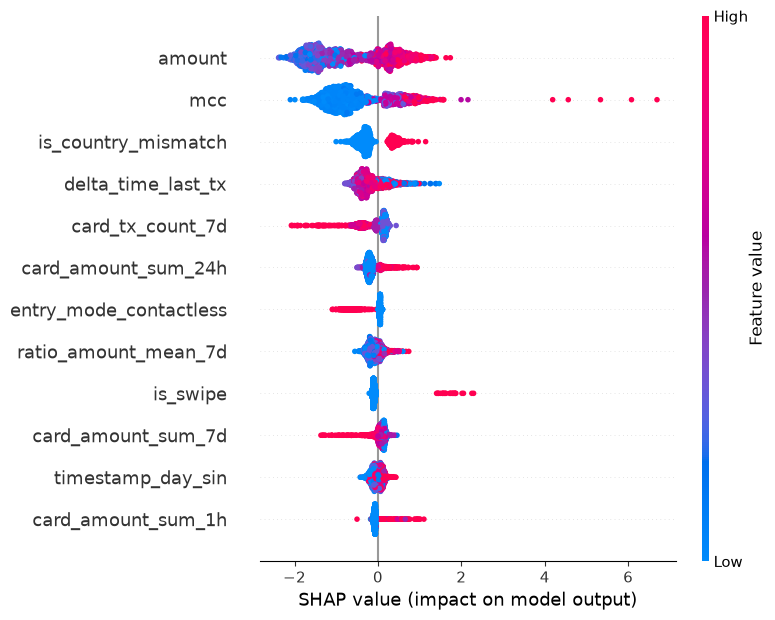

In [13]:
import matplotlib.pyplot as plt
import shap

# Muestra estratificada para renderizado rápido de beeswarm nativo de SHAP
sample_idx = np.random.RandomState(42).choice(len(Xt_test), size=2000, replace=False)
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values[sample_idx],
    Xt_test[sample_idx],
    feature_names=feature_names,
    max_display=12,
    show=True,
)

## 8. Conclusiones y Balance Financiero MRNF
1. **Impacto de la Optimización con Optuna:** El ajuste sistemático de regularización y ponderación de clases eleva el PR-AUC y reduce la tasa de falsos positivos en el umbral óptimo financiero.
2. **Aporte de la Red Tabular con Atención:** La arquitectura en PyTorch con Multi-Head Self-Attention captura interacciones cruzadas complejas entre variables de velocidad y multiplicidad de dispositivos, ofreciendo un mapa interpretable de interdependencia entre atributos.
3. **Transparencia Regulatoria:** El cálculo de TreeSHAP permite justificar con exactitud matemática cada bloqueo transaccional, cumpliendo con las directrices de explicabilidad y auditoría de MRNF.